In [2]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer
import pymorphy3
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, recall_score, classification_report, roc_curve, auc, roc_auc_score
from tqdm import tqdm
tqdm.pandas()

In [3]:
df = pd.read_json('D:/Bachelors-Thesis/data/processed/claims_v2/claims_candidates.jsonl', lines=True)

df = df[df["label"].isin(["false", "true"])].copy()
df["label"] = df["label"].map({"false": 0, "true": 1})
print(len(df))
df.tail()

24802


,id,text,label,claim_origin,review_status,label_basis,label_quality,label_bases,provenance,split_group
27188,claim_7e816403e351e932383427c0,На Харківщині виявили 44 випадки вербування ді...,1,news_headline,pending,source_based,weak,[source_based],"[{'record_id': 'gwara_274318', 'parent_id': 'g...",group_f64a725435121c1b729f
27189,claim_24bcf507496a41a37ec4a0e5,У Золочівській громаді «Молнія» поранила двох ...,1,news_headline,pending,source_based,weak,[source_based],"[{'record_id': 'gwara_274313', 'parent_id': 'g...",group_fcd398a3956cbb282115
27190,claim_c33464df1da1962510912d10,У Харкові тимчасово змінили рух тролейбусів че...,1,news_headline,pending,source_based,weak,[source_based],"[{'record_id': 'gwara_274310', 'parent_id': 'g...",group_70690a0a3217960b9c54
27191,claim_4b299483405ebd8febcf7209,На Харківщині російський дрон влучив у місцево...,1,news_headline,pending,source_based,weak,[source_based],"[{'record_id': 'gwara_274305', 'parent_id': 'g...",group_681d7e4479b113241bba
27192,claim_3773af162dd5aa7d158c53ba,У Харкові через атаку РФ на Немишлянський райо...,1,news_headline,pending,source_based,weak,[source_based],"[{'record_id': 'gwara_274299', 'parent_id': 'g...",group_40e4c08752a5a0a39cfa


In [4]:
nans = df.isnull().sum()
print(f"Number of nans: \n{nans}")

df = df.dropna(subset=["text", "label", "split_group"]).copy()
df = df[df["text"].str.strip().ne("")].reset_index(drop=True)
print(f"\nПісля видалення NaN: {len(df)} рядків")

Number of nans: 
id               0
text             0
label            0
claim_origin     0
review_status    0
label_basis      0
label_quality    0
label_bases      0
provenance       0
split_group      0
dtype: int64

Після видалення NaN: 24802 рядків


In [5]:
print(df['label'].value_counts())
print(df[df['label']==1]['text'].iloc[0])  
print(df[df['label']==0]['text'].iloc[0])  

label
1    14064
0    10738
Name: count, dtype: int64
«Якщо порівняти формулу, яку ми запропонували, з фактичною ціною імпорту, то фактична ціна імпорту була вищою навіть ніж формула»
«Питання в тому, хто це зробив? Що ж, давайте подивимося. Каховська гребля була фактично російською. Вона була побудована російською владою. Наразі вона знаходиться на території, контрольованій росією. Водосховище дамби постачає воду до Криму, який протягом останніх 240 років є домом для російського Чорноморського флоту. Підрив дамби може завдати шкоди Україні, але росії це завдасть ще більшої шкоди. Саме з цієї причини український уряд розглядав можливість її знищення.»


                               id  \
0  claim_0946a31dca2550d860488156   
1  claim_333ed1d453356f14691533c9   
2  claim_3256c6c16a99819ad6d4f219   
3  claim_f6b4fc56d70525e60deb52df   
4  claim_25ae8b5b62f4eb2487fa4942   

                                                text  label  \
0  «Питання в тому, хто це зробив? Що ж, давайте ...      0   
1  «Грошей на Флот завжди немає. Є на музеї окупа...      0   
2  «Якщо порівняти формулу, яку ми запропонували,...      1   
3  «Це механізм втручання у внутрішні справи Укра...      0   
4  «Справа зараз Митрополита Арсенія, слухання пр...      0   

                 claim_origin review_status             label_basis  \
0  explicit_verdict_and_quote       pending  explicit_claim_verdict   
1  explicit_verdict_and_quote       pending  explicit_claim_verdict   
2  explicit_verdict_and_quote       pending  explicit_claim_verdict   
3  explicit_verdict_and_quote       pending  explicit_claim_verdict   
4  explicit_verdict_and_quote       pending

Text(0.5, 1.0, 'Розподіл класів у датасеті')

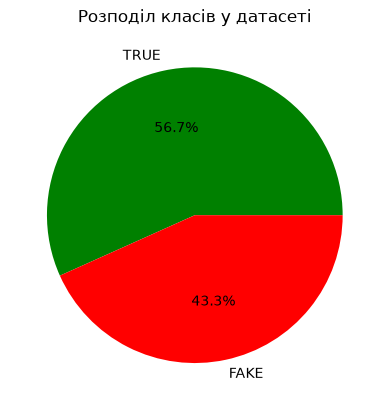

In [6]:

print(df.head())
true_count = (df['label'] == 1).sum()
fake_count = (df['label'] == 0).sum()
print(f"Number of true news: {true_count}")
print(f"Number of fake news: {fake_count}")
plt.pie([true_count, fake_count], labels=['TRUE', 'FAKE'], 
        autopct='%1.1f%%', colors=['green','red'])
plt.title('Розподіл класів у датасеті')
# plt.savefig('dataset_distribution.png')

In [7]:
with open('D:/Bachelors-Thesis/src/data/resources/stopwords_ua.txt', 'r', encoding='utf-8') as f:
    content = f.read()
    stopwords = content.strip().split()
print(stopwords[:10])

['а', 'аби', 'абиде', 'абиким', 'абикого', 'абиколи', 'абикому', 'абикуди', 'абихто', 'абичий']


In [8]:
protected_words = {
    "не", "ні", "ані", "без", "немає", "нема",
    "ніколи", "ніхто", "ніщо", "нічого", "ніде",
    "жоден", "жодний", "жодного"
}

stopwords = set(stopwords) - protected_words

In [9]:
def filtering(sentence):
    clean_text = sentence.lower()
    clean_text = clean_text.translate(str.maketrans({
    "’": "'",
    "ʼ": "'",
    "`": "'"
    }))
    clean_text = re.sub(r"[^\w\s']", " ", clean_text)
    words = clean_text.split()
    clean_text = [word for word in words if word not in stopwords]
    return ' '.join(clean_text)

text = df[["text"]].copy()
text["text"] = text["text"].apply(filtering)

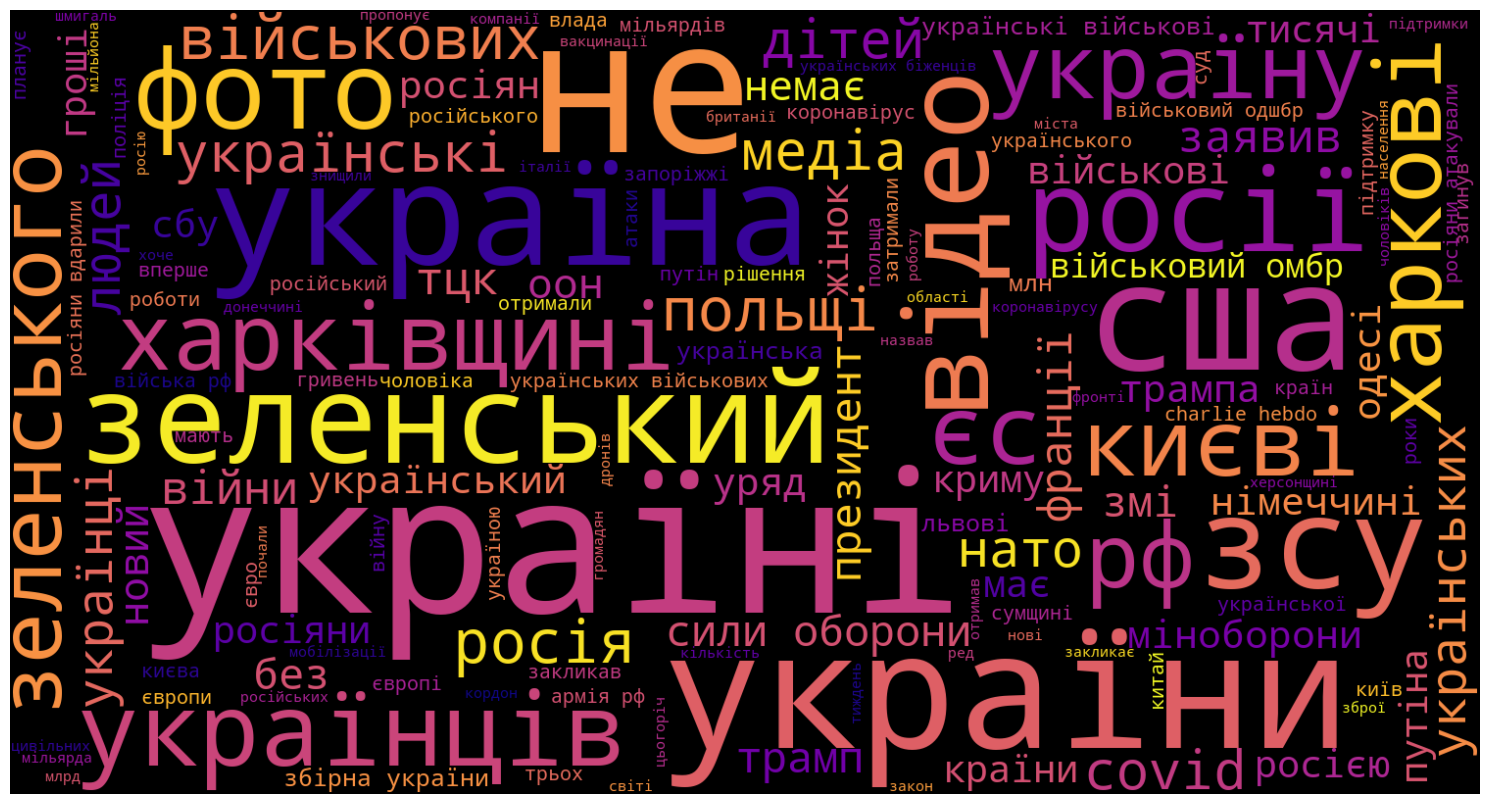

In [10]:
text_for_wordcloud = ' '.join(text['text'])
wordcloud = WordCloud(
    width=1500, 
    height=800, 
    max_words=150, 
    background_color='black',
    min_font_size=10,
    max_font_size=200,
    prefer_horizontal=0.7,
    colormap='plasma'
    )
wordcloud.generate(text_for_wordcloud)
plt.figure(figsize=(15,10))
plt.axis(False)
plt.tight_layout()
plt.imshow(wordcloud, interpolation='bilinear')


In [11]:
morph = pymorphy3.MorphAnalyzer(lang='uk')

lemma_cache = {}

def lemmatize_text(sentence):
    words = sentence.split()
    lemmas = []
    for word in words:
        if word not in lemma_cache:
            lemma_cache[word] = morph.parse(word)[0].normal_form
        lemmas.append(lemma_cache[word])
    return ' '.join(lemmas)

print(f"Before filtering: {df['text'].iloc[0]}")

text['text'] = text['text'].progress_apply(lemmatize_text)

print(f"After filtering: {text['text'].iloc[0]}")

all_words_before = ' '.join(df['text']).split()
all_words_after = ' '.join(text['text']).split()
unique_words_before_filtering = len(set(all_words_before))
unique_words_after_filtering = len(set(all_words_after))
print(f"Unique words before filtering: {unique_words_before_filtering}")
print(f"Unique words after filtering: {unique_words_after_filtering}")
decrease_percent = (unique_words_before_filtering - unique_words_after_filtering) / unique_words_before_filtering * 100
print(f"Decreased by {decrease_percent:.2f}%")

Before filtering: «Питання в тому, хто це зробив? Що ж, давайте подивимося. Каховська гребля була фактично російською. Вона була побудована російською владою. Наразі вона знаходиться на території, контрольованій росією. Водосховище дамби постачає воду до Криму, який протягом останніх 240 років є домом для російського Чорноморського флоту. Підрив дамби може завдати шкоди Україні, але росії це завдасть ще більшої шкоди. Саме з цієї причини український уряд розглядав можливість її знищення.»


100%|██████████| 24802/24802 [00:01<00:00, 12816.08it/s]

After filtering: питання зробити давати подивитися каховський гребля фактично російський побудований російський влада наразі знаходитися територія контрольований росія водосховище дамба постачати вода крим останній 240 дім російський чорноморський флот підрив дамба завдати шкода україна росія завдати більший шкода причина український уряд розглядати можливість знищення
Unique words before filtering: 52445
Unique words after filtering: 19618
Decreased by 62.59%


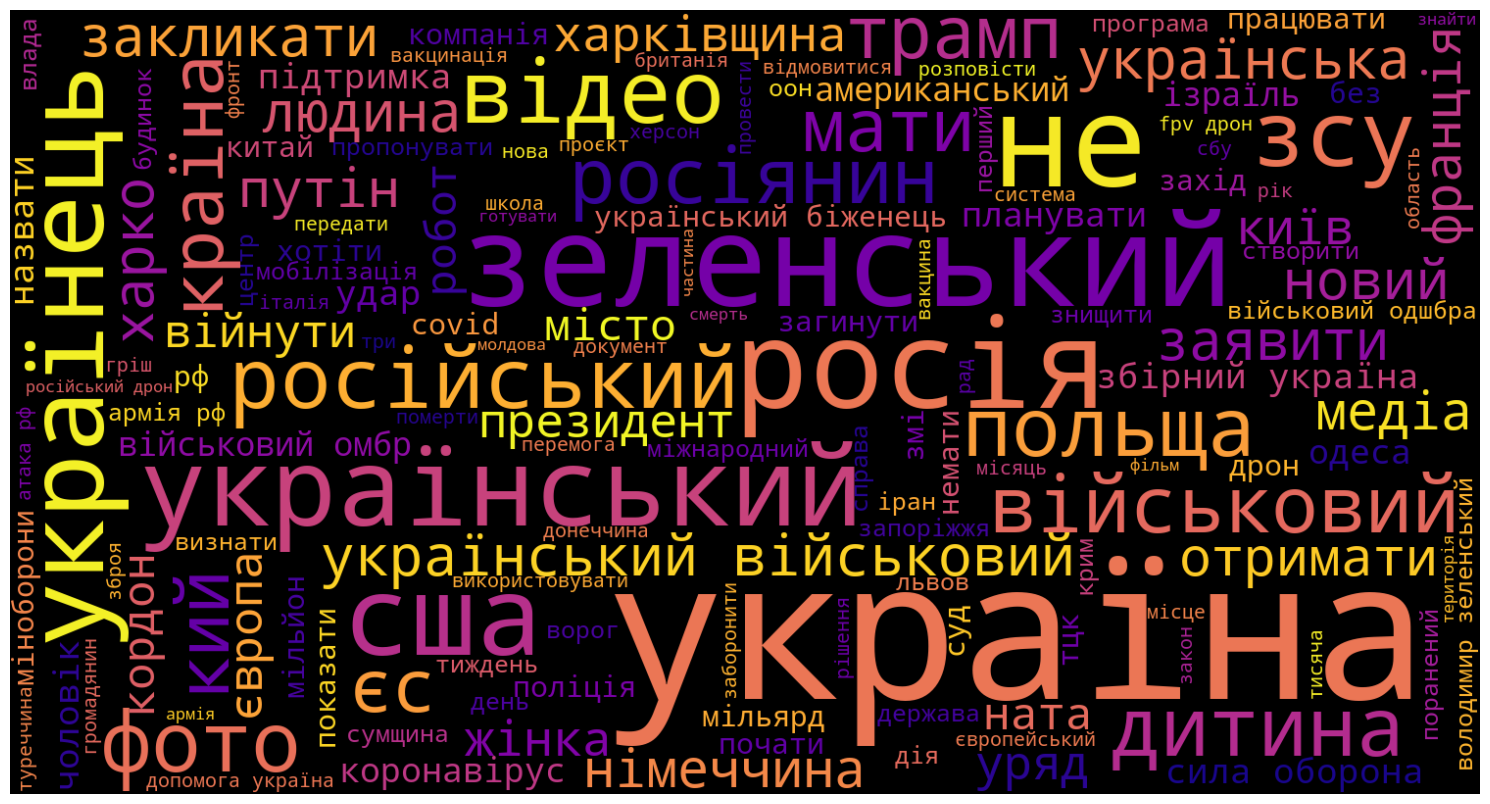

In [12]:
text_for_wordcloud = ' '.join(text['text'])
wordcloud = WordCloud(
    width=1500, 
    height=800, 
    max_words=150, 
    background_color='black',
    min_font_size=10,
    max_font_size=200,
    prefer_horizontal=0.7,
    colormap='plasma'
    )
wordcloud.generate(text_for_wordcloud)
plt.figure(figsize=(15,10))
plt.axis(False)
plt.tight_layout()
plt.imshow(wordcloud, interpolation='bilinear')
plt.savefig('wordcloud_after_lemma.png', dpi=150, bbox_inches='tight')

In [13]:
X = text['text'].values
Y = df['label'].values
print(X[:5])
print(Y[:5])

<StringArray>
['питання зробити давати подивитися каховський гребля фактично російський побудований російський влада наразі знаходитися територія контрольований росія водосховище дамба постачати вода крим останній 240 дім російський чорноморський флот підрив дамба завдати шкода україна росія завдати більший шкода причина український уряд розглядати можливість знищення',
                                                                                                     'гроші флот немати музей окупація еміграція впровадження інновація ніхто не знати туристичний магніт громадське телебачення зарплата член наглядовий рад голови держмонополія без прив'язка ефективність перейменування вулиця місто без прив'язка адекватність',
                                                                                                                                                                                                                                                                            

In [14]:
print(f"X shape: {X.shape}")
print(f"Y shape: {Y.shape}")

X shape: (24802,)
Y shape: (24802,)


In [15]:
print(X)

<StringArray>
[                                                                                                             'питання зробити давати подивитися каховський гребля фактично російський побудований російський влада наразі знаходитися територія контрольований росія водосховище дамба постачати вода крим останній 240 дім російський чорноморський флот підрив дамба завдати шкода україна росія завдати більший шкода причина український уряд розглядати можливість знищення',
                                                                                                                                                                                                                  'гроші флот немати музей окупація еміграція впровадження інновація ніхто не знати туристичний магніт громадське телебачення зарплата член наглядовий рад голови держмонополія без прив'язка ефективність перейменування вулиця місто без прив'язка адекватність',
                                                  

In [16]:
groups = df["split_group"].to_numpy()

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, test_idx = next(splitter.split(X, Y, groups))

X_train_text = X[train_idx]
X_test_text = X[test_idx]
Y_train = Y[train_idx]
Y_test = Y[test_idx]

assert not set(groups[train_idx]) & set(groups[test_idx])
assert set(Y_train) == set(Y_test) == {0, 1}

vectorizer = TfidfVectorizer(
    max_features=30000,
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.9,
    sublinear_tf=True
)

X_train = vectorizer.fit_transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

print(f"Навчальних прикладів: {len(Y_train)}")
print(f"Тестових прикладів: {len(Y_test)}")
print(f"Ознак: {X_train.shape[1]}")
print("Train:", pd.Series(Y_train).value_counts().to_dict())
print("Test:", pd.Series(Y_test).value_counts().to_dict())

Навчальних прикладів: 19845
Тестових прикладів: 4957
Ознак: 23492
Train: {1: 11253, 0: 8592}
Test: {1: 2811, 0: 2146}


In [17]:
split_dir = Path("D:/Bachelors-Thesis/data/splits")
split_dir.mkdir(parents=True, exist_ok=True)
split = np.full(len(df), "train", dtype=object)
split[test_idx] = "test"
pd.DataFrame({"id": df["id"], "split": split}).to_csv(split_dir / "claims_v2_split.csv", index=False)

In [25]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=30000, min_df=2, max_df=0.9, sublinear_tf=True)),
    ("clf", LogisticRegression(solver="saga", class_weight="balanced",
                               max_iter=2000, random_state=42)),
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "clf__C": [0.25, 0.5, 1, 2, 4, 8, 16, 32],
}

inner_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
search = GridSearchCV(pipeline, param_grid, scoring="f1_macro",
                      cv=inner_cv, n_jobs=-1, verbose=1)
search.fit(X_train_text, Y_train, groups=groups[train_idx])

sweep = pd.DataFrame(search.cv_results_)[
    ["param_tfidf__ngram_range", "param_clf__C", "mean_test_score", "std_test_score"]
].sort_values("mean_test_score", ascending=False)
sweep.to_csv("D:/Bachelors-Thesis/experiments/results/logreg_sweep.csv", index=False)
print("Найкращі параметри:", search.best_params_)
print(f"Macro-F1 на крос-валідації (train): {search.best_score_:.4f}")
display(sweep.head(10))

vectorizer = search.best_estimator_["tfidf"]
model_detector = search.best_estimator_["clf"]
X_train = vectorizer.transform(X_train_text)
X_test = vectorizer.transform(X_test_text)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Найкращі параметри: {'clf__C': 8, 'tfidf__ngram_range': (1, 2)}
Macro-F1 на крос-валідації (train): 0.8829


,param_tfidf__ngram_range,param_clf__C,mean_test_score,std_test_score
11,"(1, 2)",8.0,0.882913,0.006193
9,"(1, 2)",4.0,0.882745,0.006166
13,"(1, 2)",16.0,0.881948,0.005497
7,"(1, 2)",2.0,0.880286,0.007508
15,"(1, 2)",32.0,0.879442,0.006128
8,"(1, 1)",4.0,0.876012,0.006934
5,"(1, 2)",1.0,0.875000,0.006600
6,"(1, 1)",2.0,0.874507,0.007018
10,"(1, 1)",8.0,0.874386,0.005166
12,"(1, 1)",16.0,0.872203,0.006336


In [19]:
X_train_prediction = model_detector.predict(X_train)
training_data_accuracy = accuracy_score(X_train_prediction, Y_train)
print(f"Accuracy score of the training data: {training_data_accuracy * 100:.2f}%")

Accuracy score of the training data: 99.01%


In [20]:
X_test_prediction = model_detector.predict(X_test)
test_data_accuracy = accuracy_score(X_test_prediction, Y_test)
print(f"Accuracy score of the test data: {test_data_accuracy * 100:.2f}%")
print(f"Macro-F1: {f1_score(Y_test, X_test_prediction, average='macro'):.4f}")

Accuracy score of the test data: 88.74%
Macro-F1: 0.8856


In [21]:
print("Classification Report:")
print(classification_report(Y_test, X_test_prediction, target_names=['Fake', 'True']))

Classification Report:
              precision    recall  f1-score   support

        Fake       0.86      0.88      0.87      2146
        True       0.91      0.89      0.90      2811

    accuracy                           0.89      4957
   macro avg       0.88      0.89      0.89      4957
weighted avg       0.89      0.89      0.89      4957



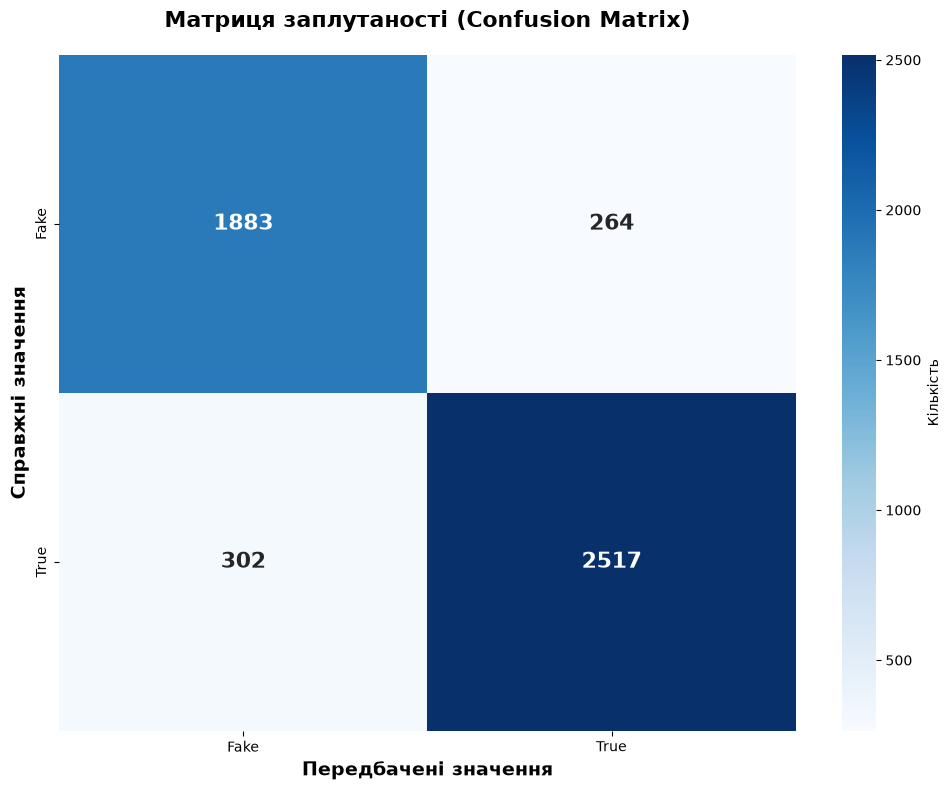


ДЕТАЛЬНА СТАТИСТИКА МАТРИЦІ ЗАПЛУТАНОСТІ
True Negatives (TN): 1883 - правильно визначені FAKE
False Positives (FP): 264 - помилково визначені як TRUE
False Negatives (FN): 302 - помилково визначені як FAKE
True Positives (TP): 2517 - правильно визначені TRUE


In [161]:
import seaborn as sns

cm = confusion_matrix(Y_test, X_test_prediction)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm, 
    annot=True, 
    fmt='d', 
    cmap='Blues',
    xticklabels=['Fake', 'True'],
    yticklabels=['Fake', 'True'],
    cbar_kws={'label': 'Кількість'},
    annot_kws={'size': 16, 'weight': 'bold'}
)
plt.title('Матриця заплутаності (Confusion Matrix)', fontsize=16, weight='bold', pad=20)
plt.ylabel('Справжні значення', fontsize=14, weight='bold')
plt.xlabel('Передбачені значення', fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

print("\n" + "="*60)
print("ДЕТАЛЬНА СТАТИСТИКА МАТРИЦІ ЗАПЛУТАНОСТІ")
print("="*60)
print(f"True Negatives (TN): {cm[0][0]} - правильно визначені FAKE")
print(f"False Positives (FP): {cm[0][1]} - помилково визначені як TRUE")
print(f"False Negatives (FN): {cm[1][0]} - помилково визначені як FAKE")
print(f"True Positives (TP): {cm[1][1]} - правильно визначені TRUE")
print("="*60)

In [22]:
input_news = "23 вересня делегація Львівського національного університету імені Івана Франка на чолі з проректором з науково-педагогічної роботи та соціально-гуманітарного розвитку, професором Олегом Бугрієм, взяла участь у передконференційному семінарі «Кібербезпека на основі штучного інтелекту: нові можливості та виклики», проведеному в межах міжнародного проєкту «AI-Driven Cybersecurity: Opportunities and Challenges»"

In [23]:
filtered_news = filtering(input_news)
input_text = lemmatize_text(filtered_news)
input_vector = vectorizer.transform([input_text])
prediction = model_detector.predict(input_vector)
prob = model_detector.predict_proba(input_vector)
input_text

'23 вересень делегація львівський національний університет іван франк проректор науково педагогічний робот соціально гуманітарний розвиток професор олег бугрій взяти участь передконференційний семінар кібербезпека штучний інтелект новий можливість виклик проведений межа міжнародний проєкт ai driven cybersecurity opportunities and challenges'

In [24]:
def true_or_false(prob):
    if prob[0][1] > 0.5:
        label = "true"
        probability = prob[0][1]
    else:
        label = "false"
        probability = prob[0][0]
    return label, probability

label, probability = true_or_false(prob)
print(f"Прогноз класифікатора: {label}, впевненість моделі {probability * 100:.2f}%")

Прогноз класифікатора: true, впевненість моделі 98.28%


In [ ]:
import pickle
with open('D:/Bachelors-Thesis/models/fake_true_vectorizer.pkl', 'wb') as f:
    pickle.dump(vectorizer, f)

with open('D:/Bachelors-Thesis/models/model_detector.pkl', 'wb') as f:
    pickle.dump(model_detector, f)

In [28]:
test_df = df.iloc[test_idx].copy()
test_df["pred"] = model_detector.predict(X_test)
test_df["source"] = test_df["provenance"].apply(
    lambda items: ", ".join(sorted({item["source"] for item in items})))

by_source = test_df.groupby("source").apply(
    lambda g: pd.Series({
        "n": len(g),
        "true_share": (g["label"] == 1).mean(),
        "accuracy": (g["label"] == g["pred"]).mean(),
    }))
display(by_source.sort_values("n", ascending=False))

,n,true_share,accuracy
source,,,
ukrinform,2341.0,1.000000,0.897053
voxcheck,1263.0,0.051465,0.876485
stopfake,676.0,0.000000,0.880178
gwara,538.0,0.723048,0.912639
bezbrehni,136.0,0.110294,0.757353
"stopfake, voxcheck",2.0,0.000000,1.000000
"gwara, ukrinform",1.0,1.000000,1.000000


In [30]:
test_df["correct"] = test_df["label"] == test_df["pred"]
by_source_label = test_df.groupby(["source", "label"])["correct"].agg(
    n="size", accuracy="mean")
display(by_source_label)

n  accuracy
source             label                
bezbrehni          0       121  0.785124
                   1        15  0.533333
gwara              0       149  0.845638
                   1       389  0.938303
gwara, ukrinform   1         1  1.000000
stopfake           0       676  0.880178
stopfake, voxcheck 0         2  1.000000
ukrinform          1      2341  0.897053
voxcheck           0      1198  0.891486
                   1        65  0.600000

In [31]:
by_source_label.to_csv("D:/Bachelors-Thesis/experiments/results/logreg_by_source_label.csv")